In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import sklearn

print("Python location:", sys.executable)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)

Python location: C:\Users\Hp\anaconda3\envs\ml\python.exe
NumPy: 2.5.3
pandas: 3.0.6
Matplotlib: 3.11.2
scikit-learn: 1.9.1


In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"

df = pd.read_csv(DATA / "titanic_dataset.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print("Data types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isna().sum())

print("\nSurvival proportions:")
print(df["Survived"].value_counts(normalize=True))

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Missing values per column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Survival proportions:
Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


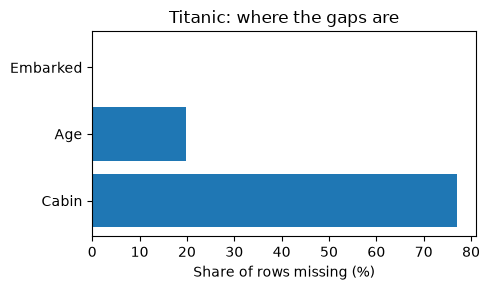

In [4]:
import matplotlib.pyplot as plt

missing = df.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]

plt.figure(figsize=(5, 3))
plt.barh(missing.index, missing.values * 100)
plt.xlabel("Share of rows missing (%)")
plt.title("Titanic: where the gaps are")
plt.tight_layout()
plt.show()

In [5]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
df["Title"] = df["Title"].where(
    df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]),
    "Other"
)

df["LogFare"] = np.log1p(df["Fare"])

display(df[["Name", "Title", "FamilySize", "IsAlone", "Fare", "LogFare"]].head())

print("\nTitle counts:")
print(df["Title"].value_counts())

,Name,Title,FamilySize,IsAlone,Fare,LogFare
0,"Braund, Mr. Owen Harris",Mr,2,0,7.2500,2.110213
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,2,0,71.2833,4.280593
2,"Heikkinen, Miss. Laina",Miss,1,1,7.9250,2.188856
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,2,0,53.1000,3.990834
4,"Allen, Mr. William Henry",Mr,1,1,8.0500,2.202765



Title counts:
Title
Mr        517
Miss      182
Mrs       125
Master     40
Other      27
Name: count, dtype: int64


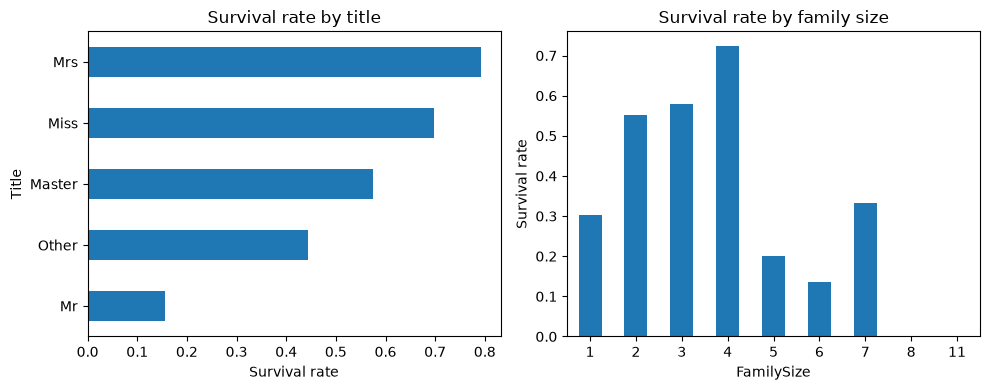

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

df.groupby("Title")["Survived"].mean().sort_values().plot.barh(
    ax=axes[0]
)
axes[0].set_xlabel("Survival rate")
axes[0].set_title("Survival rate by title")

df.groupby("FamilySize")["Survived"].mean().plot.bar(
    ax=axes[1], rot=0
)
axes[1].set_ylabel("Survival rate")
axes[1].set_title("Survival rate by family size")

plt.tight_layout()
plt.show()

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Prepare numeric and categorical columns separately.
def make_preprocess(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), num_cols),

        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), cat_cols),
    ])

y = df["Survived"]

feature_sets = {
    "raw columns": (
        ["Age", "SibSp", "Parch", "Fare"],
        ["Pclass", "Sex", "Embarked"]
    ),
    "raw + engineered": (
        ["Age", "SibSp", "Parch", "LogFare", "FamilySize", "IsAlone"],
        ["Pclass", "Sex", "Embarked", "Title"]
    ),
}

for name, (num_cols, cat_cols) in feature_sets.items():
    X = df[num_cols + cat_cols]

    X_train, X_valid, y_train, y_valid = train_test_split(
        X, y,
        test_size=0.25,
        random_state=42,
        stratify=y
    )

    model = Pipeline([
        ("preprocess", make_preprocess(num_cols, cat_cols)),
        ("model", LogisticRegression(max_iter=2000)),
    ])

    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_valid)[:, 1]
    auc = roc_auc_score(y_valid, probabilities)

    print(f"{name:18s} validation ROC AUC = {auc:.3f}")

raw columns        validation ROC AUC = 0.842
raw + engineered   validation ROC AUC = 0.872


In [8]:
cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")

feature_cols = [
    c for c in cancer.columns
    if c not in {"id", "diagnosis", "Unnamed: 32"}
]

X_cancer = cancer[feature_cols]

three = ["area_mean", "texture_mean", "smoothness_mean"]

print(X_cancer[three].describe().loc[["mean", "std"]].round(3))

      area_mean  texture_mean  smoothness_mean
mean    654.889        19.290            0.096
std     351.914         4.301            0.014


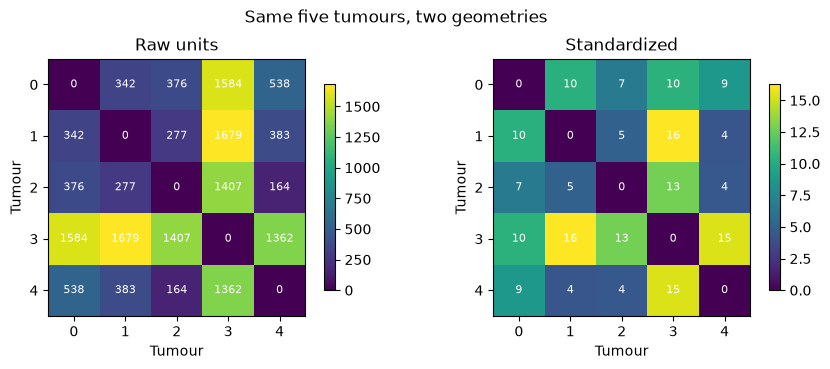

In [9]:
from sklearn.metrics import pairwise_distances

# Calculate distances using all measurement columns.
raw = pairwise_distances(X_cancer.iloc[:5], metric="euclidean")

X_scaled = StandardScaler().fit_transform(X_cancer)
scaled = pairwise_distances(X_scaled[:5], metric="euclidean")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))

for ax, matrix, title in [
    (axes[0], raw, "Raw units"),
    (axes[1], scaled, "Standardized")
]:
    im = ax.imshow(matrix, cmap="viridis")
    ax.set_title(title)
    ax.set_xlabel("Tumour")
    ax.set_ylabel("Tumour")

    for i in range(5):
        for j in range(5):
            ax.text(
                j, i, f"{matrix[i, j]:.0f}",
                ha="center", va="center",
                color="white", fontsize=8
            )

    fig.colorbar(im, ax=ax, shrink=0.8)

plt.suptitle("Same five tumours, two geometries")
plt.tight_layout()
plt.show()

In [10]:
for name, matrix in [("Raw", raw), ("Standardized", scaled)]:
    distances = matrix.copy()
    np.fill_diagonal(distances, np.inf)

    i, j = np.unravel_index(np.argmin(distances), distances.shape)

    print(
        f"{name}: tumours {i + 1} and {j + 1}, "
        f"distance = {matrix[i, j]:.3f}"
    )

Raw: tumours 3 and 5, distance = 164.155
Standardized: tumours 2 and 5, distance = 4.379


In [11]:
students = pd.read_csv(DATA / "student_performance_dataset.csv")

print("Shape:", students.shape)
print("Missing values:", students.isna().sum().sum())
print("Duplicate rows:", students.duplicated().sum())

target = "G3"
leaky = ["G1", "G2"]

X_s = students.drop(columns=[target] + leaky)
y_s = students[target]

s_num = X_s.select_dtypes(include="number").columns.tolist()
s_cat = X_s.select_dtypes(exclude="number").columns.tolist()

print("Numeric features:", len(s_num))
print("Categorical features:", len(s_cat))

Xs_train, Xs_valid, ys_train, ys_valid = train_test_split(
    X_s, y_s, test_size=0.25, random_state=42
)

Shape: (649, 33)
Missing values: 0
Duplicate rows: 0
Numeric features: 13
Categorical features: 17


In [12]:
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_absolute_error

def evaluate(pipeline, X_tr, X_va, label):
    pipeline.fit(X_tr, ys_train)
    predictions = pipeline.predict(X_va)
    mae = mean_absolute_error(ys_valid, predictions)

    print(f"{label:32s} validation MAE = {mae:.3f} grade points")
    return mae

results = {}

# 1. Ridge using all candidate features
results["all 30 features"] = evaluate(
    Pipeline([
        ("preprocess", make_preprocess(s_num, s_cat)),
        ("model", Ridge(alpha=1.0)),
    ]),
    Xs_train, Xs_valid, "all 30 features"
)

# 2. Select 10 processed columns, then train Ridge
results["SelectKBest, k=10"] = evaluate(
    Pipeline([
        ("preprocess", make_preprocess(s_num, s_cat)),
        ("select", SelectKBest(f_regression, k=10)),
        ("model", Ridge(alpha=1.0)),
    ]),
    Xs_train, Xs_valid, "SelectKBest, k=10"
)

# 3. Lasso performs selection through zero coefficients
lasso = Pipeline([
    ("preprocess", make_preprocess(s_num, s_cat)),
    ("model", Lasso(alpha=0.1)),
])

results["lasso (selects itself)"] = evaluate(
    lasso,
    Xs_train, Xs_valid, "lasso (selects itself)"
)

all 30 features                  validation MAE = 2.181 grade points
SelectKBest, k=10                validation MAE = 2.139 grade points
lasso (selects itself)           validation MAE = 2.077 grade points


In [13]:
# Deliberate leakage demonstration: G2 is unavailable at enrolment.
leak_num = s_num + ["G2"]

results["all 30 + G2 (leakage)"] = evaluate(
    Pipeline([
        ("preprocess", make_preprocess(leak_num, s_cat)),
        ("model", Ridge(alpha=1.0)),
    ]),
    Xs_train.assign(G2=students.loc[Xs_train.index, "G2"]),
    Xs_valid.assign(G2=students.loc[Xs_valid.index, "G2"]),
    "all 30 + G2 (leakage)"
)

all 30 + G2 (leakage)            validation MAE = 0.762 grade points


Lasso kept 18 of 56 encoded columns
num__failures            -9.416473e-01
cat__higher_no           -7.922330e-01
num__Dalc                -3.491674e-01
cat__reason_other        -2.290456e-01
num__health              -1.848847e-01
num__freetime            -2.401585e-02
num__goout               -1.425148e-02
num__absences            -1.352959e-02
num__traveltime          -7.864450e-03
cat__school_MS           -1.017754e-15
cat__higher_yes           4.515940e-15
cat__reason_reputation    4.170701e-02
num__famrel               9.778877e-02
num__Fedu                 1.003059e-01
num__Medu                 1.687337e-01
num__studytime            3.331628e-01
cat__schoolsup_no         3.557441e-01
cat__school_GP            1.105379e+00
dtype: float64


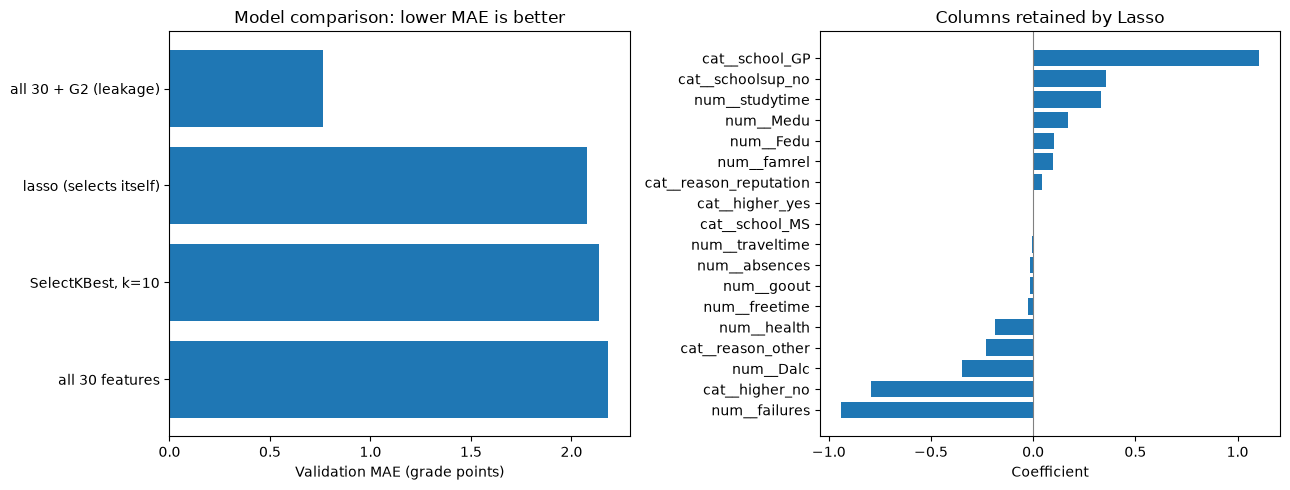

In [14]:
coefs = pd.Series(
    lasso.named_steps["model"].coef_,
    index=lasso.named_steps["preprocess"].get_feature_names_out()
)

kept = coefs[coefs != 0].sort_values()

print(f"Lasso kept {len(kept)} of {len(coefs)} encoded columns")
print(kept)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].barh(list(results.keys()), list(results.values()))
axes[0].set_xlabel("Validation MAE (grade points)")
axes[0].set_title("Model comparison: lower MAE is better")

axes[1].barh(kept.index, kept.values)
axes[1].axvline(0, color="grey", linewidth=0.8)
axes[1].set_xlabel("Coefficient")
axes[1].set_title("Columns retained by Lasso")

plt.tight_layout()
plt.show()

In [15]:
k_results = {10: results["SelectKBest, k=10"]}

for k in [5, 20]:
    pipeline = Pipeline([
        ("preprocess", make_preprocess(s_num, s_cat)),
        ("select", SelectKBest(f_regression, k=k)),
        ("model", Ridge(alpha=1.0)),
    ])

    k_results[k] = evaluate(
        pipeline,
        Xs_train,
        Xs_valid,
        f"SelectKBest, k={k}"
    )

print("\nComparison:")
for k in sorted(k_results):
    print(f"k={k:2d}: MAE = {k_results[k]:.3f}")

SelectKBest, k=5                 validation MAE = 2.134 grade points
SelectKBest, k=20                validation MAE = 2.125 grade points

Comparison:
k= 5: MAE = 2.134
k=10: MAE = 2.139
k=20: MAE = 2.125


In [16]:
df["FarePerPerson"] = df["Fare"] / df["FamilySize"]

base_num = ["Age", "SibSp", "Parch", "LogFare", "FamilySize", "IsAlone"]
base_cat = ["Pclass", "Sex", "Embarked", "Title"]

titanic_results = {}

for label, num_cols in [
    ("Engineered baseline", base_num),
    ("+ FarePerPerson", base_num + ["FarePerPerson"])
]:
    X_t = df[num_cols + base_cat]
    y_t = df["Survived"]

    Xt_train, Xt_valid, yt_train, yt_valid = train_test_split(
        X_t, y_t,
        test_size=0.25,
        random_state=42,
        stratify=y_t
    )

    titanic_model = Pipeline([
        ("preprocess", make_preprocess(num_cols, base_cat)),
        ("model", LogisticRegression(max_iter=2000)),
    ])

    titanic_model.fit(Xt_train, yt_train)

    probabilities = titanic_model.predict_proba(Xt_valid)[:, 1]
    auc = roc_auc_score(yt_valid, probabilities)
    titanic_results[label] = auc

    print(f"{label:22s} validation ROC AUC = {auc:.3f}")

Engineered baseline    validation ROC AUC = 0.872
+ FarePerPerson        validation ROC AUC = 0.872


1. Why split the data before preprocessing that learns from it?

To prevent data leakage. Imputation values, scaling statistics, and feature selection must be learned from the training data only. The fitted transformations are then applied to validation/test data, keeping evaluation independent of training.

2. What is the difference between an identifier, a feature, and a label?

Term	Meaning	Titanic example
Identifier	Identifies a particular record; normally excluded from predictors.	PassengerId
Feature	Input used to make a prediction.	Age, Pclass, FamilySize
Label	Target outcome the model learns to predict.	Survived

3. Why must we know the prediction time to identify leakage?

A feature must be available at the moment the prediction is made. For example, G2 is leakage when predicting final grades at enrolment because it is a future grade. It can be valid when predicting after second-period grades have been released.